# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import SeasonVaryingCDDDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/season_varying_cdd/ChangeDetectionDataset/Real/subset/train/",
}
dataset = SeasonVaryingCDDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 10000


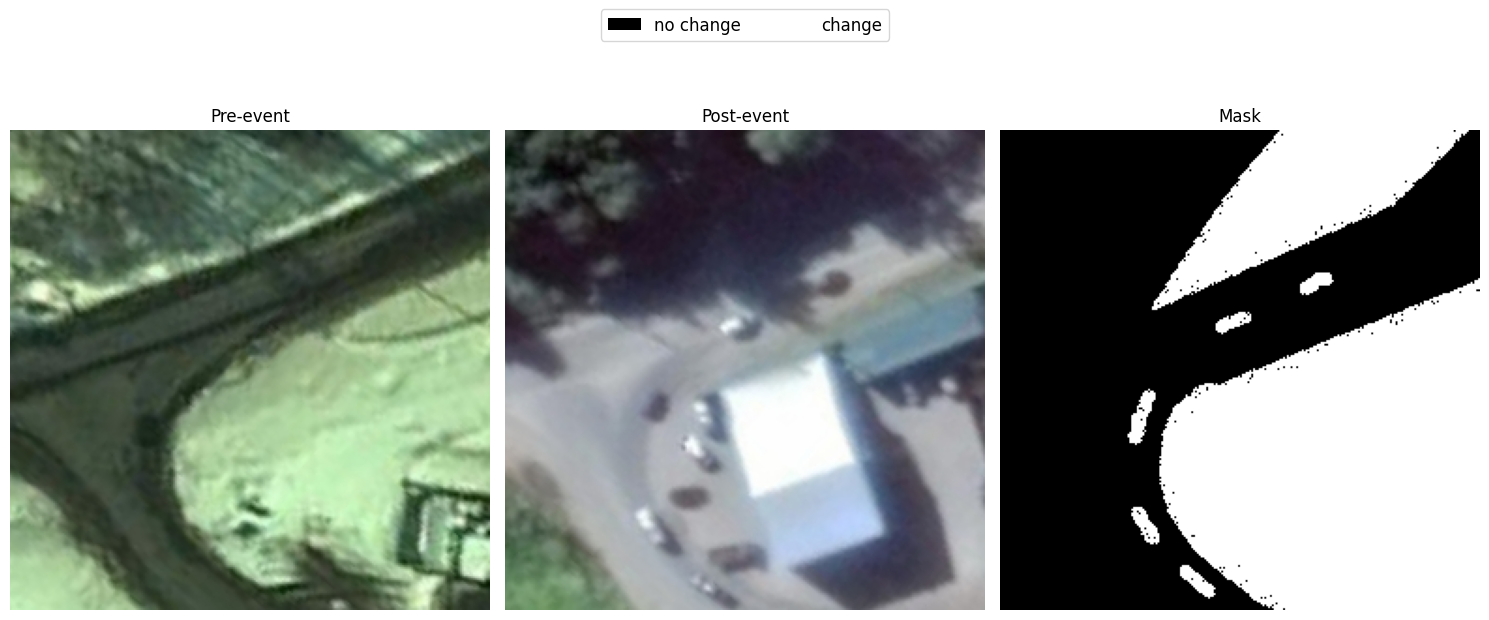

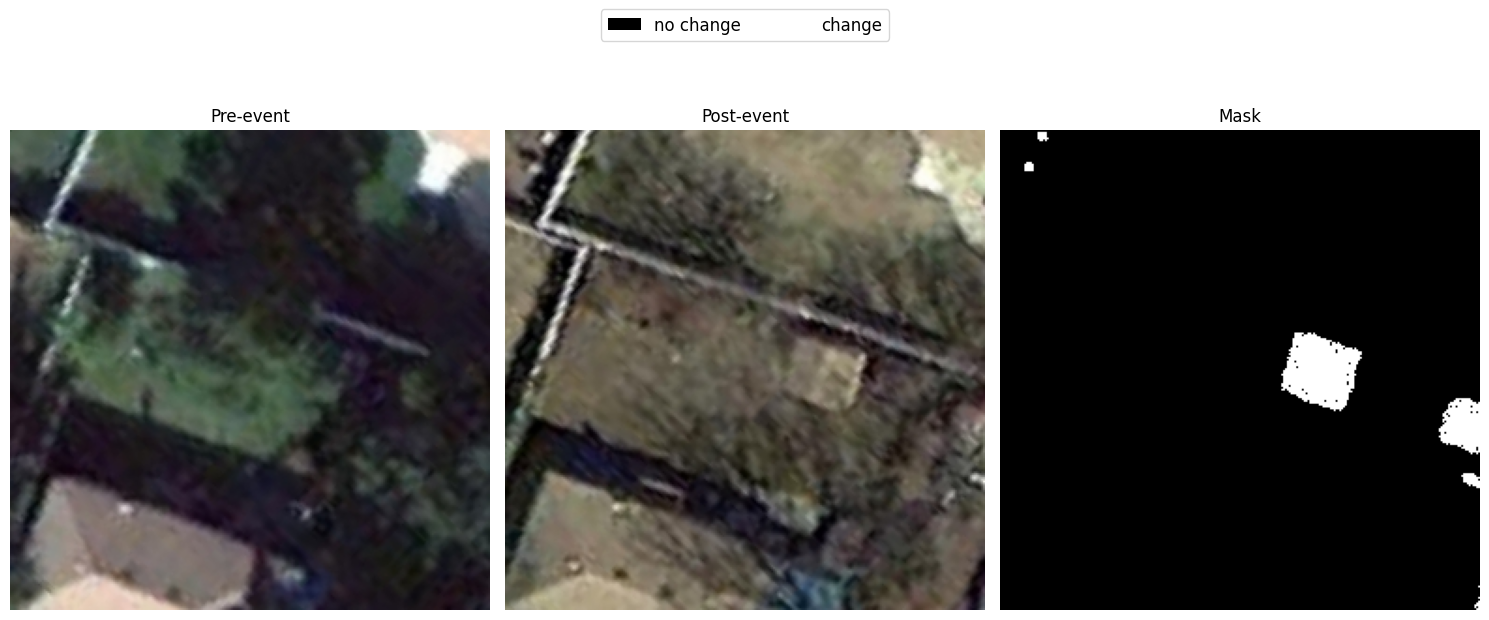

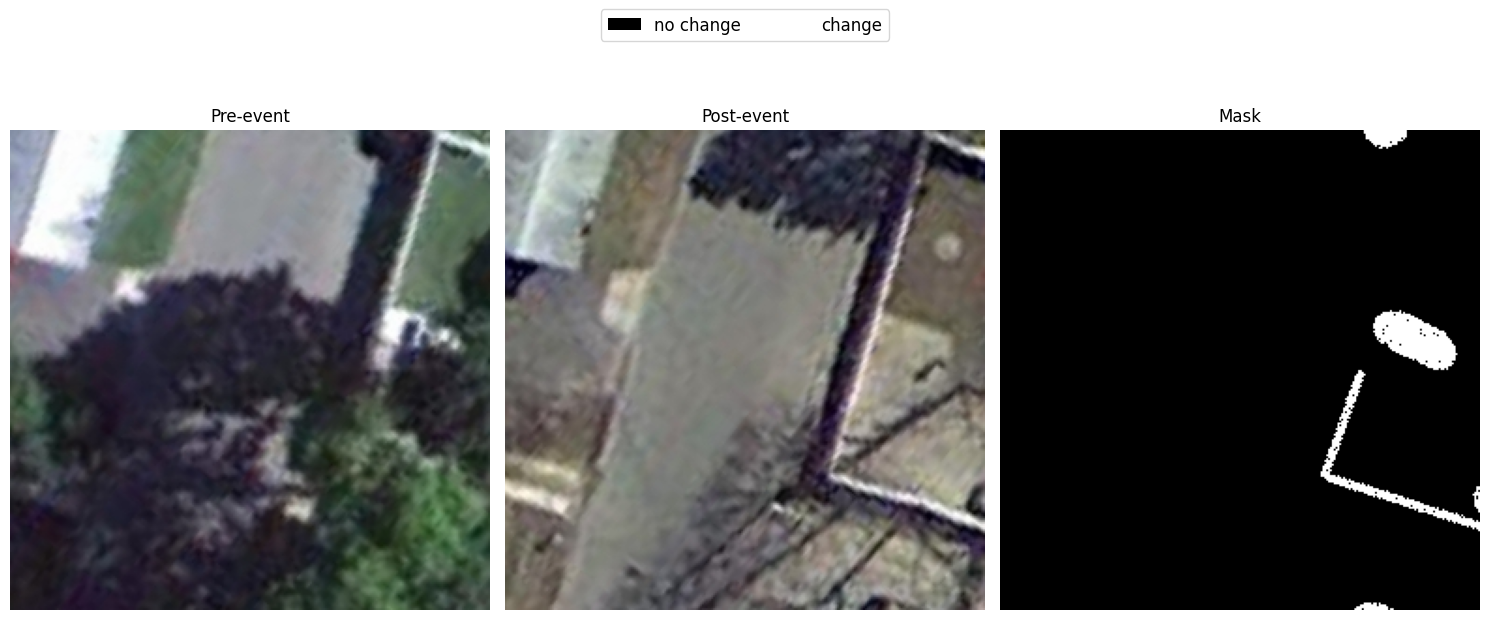

In [6]:
dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(22);

In [11]:
dataset.data_distribution_table()

,Number of pixels
no change,578682168.0
change,76677832.0


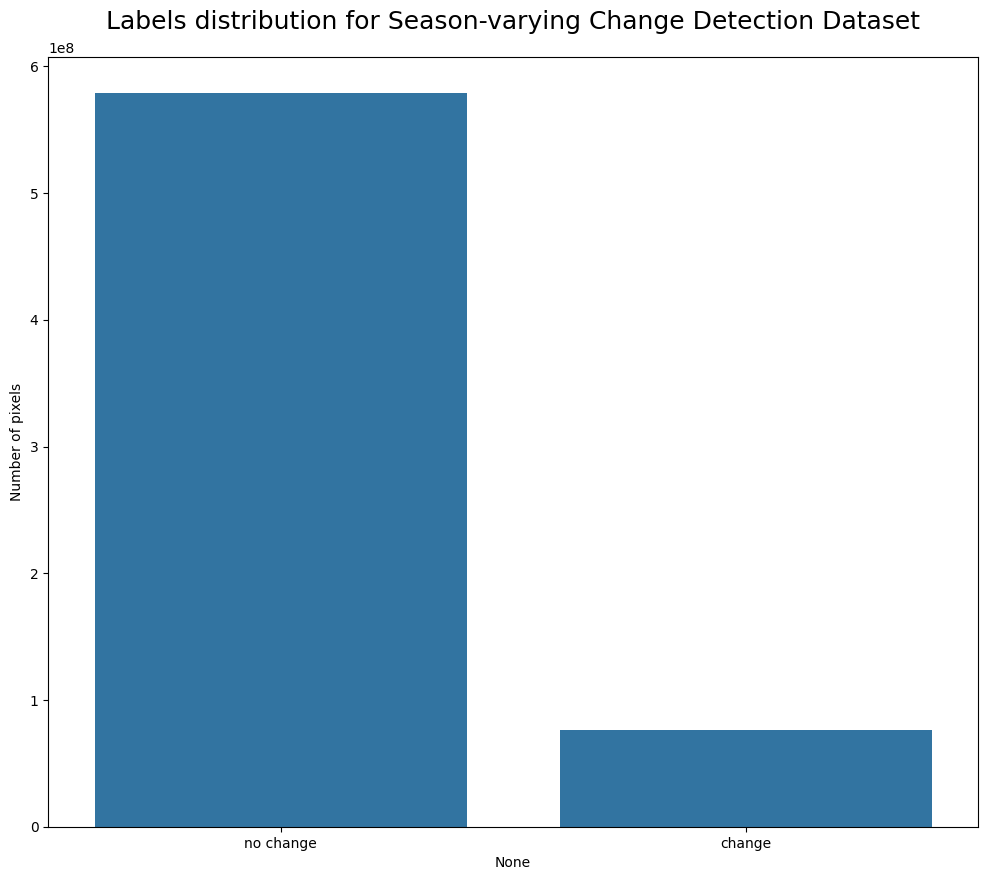

In [12]:
dataset.data_distribution_barchart();

## Load training and test data

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/season_varying_cdd/ChangeDetectionDataset/Real/subset/train/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = SeasonVaryingCDDDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/season_varying_cdd/ChangeDetectionDataset/Real/subset/val/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = SeasonVaryingCDDDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(10000, 2998)

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/season_varying_cdd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [9]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path) 
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-23 13:16:17,146 INFO Starting training.
training: 100%|██████████| 625/625 [04:34<00:00,  2.28it/s]
2026-01-23 13:20:51,759 INFO epoch: 1, loss:  0.16951
testing on train set: 100%|██████████| 625/625 [04:33<00:00,  2.28it/s]
2026-01-23 13:25:26,688 INFO Accuracy:0.8830118721008301, Accuracy per Class:[0.88299973 0.88302401], Precision Micro:0.8830595505532809, Precision Macro:0.725640825454426, Precision Weighted:0.8462676465031521, Precision per Class:[0.88311754 0.56816411], Recall Micro:0.8829496383666993, Recall Macro:0.5003598628673802, Recall Weighted:0.8829496383666993, Recall per Class:[9.99825739e-01 8.93987196e-04], F1_score Micro:0.8830045910396538, F1_score Macro:0.46981995651724956, F1_score Weighted:0.82833358947151, F1_score per Class:[0.93785475 0.00178517], IOU:0.7905176547337105, IOU mean:0.4419375056594675, IOU per Class:[0.88298163 0.00089338]
training: 100%|██████████| 625/625 [05:43<00:00,  1.82it/s]
2026-01-23 13:31:09,900 INFO epoch: 2, loss:  0.14190
t

## Predictions

2026-01-23 21:48:35,371 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/season_varying_cdd/checkpoint.pth.tar
2026-01-23 21:48:35,726 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/season_varying_cdd/checkpoint.pth.tar at epoch 51


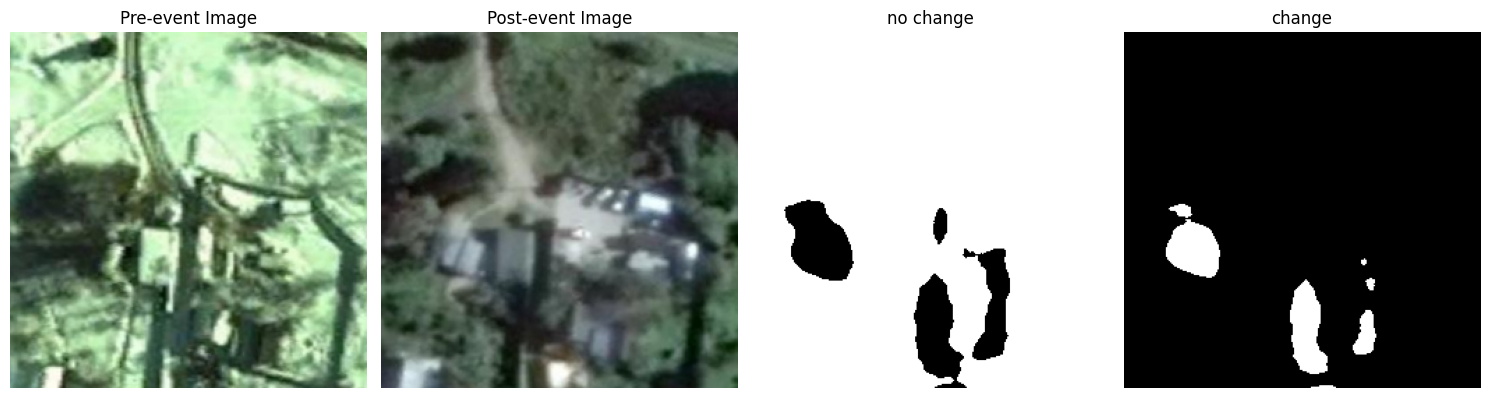

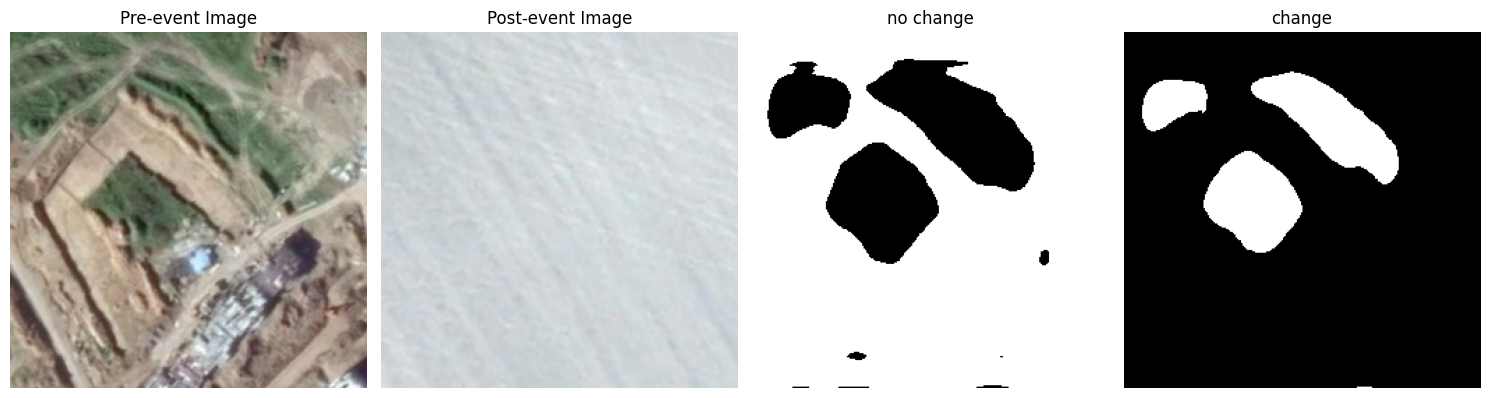

In [ ]:
model_path = "./data/experiments/season_varying_cdd/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("./data/season_varying_cdd/ChangeDetectionDataset/Real/subset/test/A/00001.jpg")
image2 = image_loader("./data/season_varying_cdd/ChangeDetectionDataset/Real/subset/test/B/00001.jpg")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("./data/season_varying_cdd/ChangeDetectionDataset/Real/subset/test/A/01900.jpg")
image2 = image_loader("./data/season_varying_cdd/ChangeDetectionDataset/Real/subset/test/B/01900.jpg")
fig = model.predict_masks(image1, image2, labels, transform)